In [1]:
# 01. Business Problem
USE_CASE = "24 - Material Auto Classification (NLP: Automatically Classify Materials from Descriptions)"
ML_PARADIGM = "Unsupervised NLP & Clustering (5 Unsupervised Models Ranked -> 1 Champion Model Selected)"
SCHEMAS = ["HANA_P2", "HANA_P3"]
N_CLUSTERS = 4

print(f"Business Problem: {USE_CASE}")
print(f"ML Approach:      {ML_PARADIGM}")
print(f"Target Schemas:   {SCHEMAS} (Complete Server Dataset - No Row Limit)")
print(f"Target Segments:  {N_CLUSTERS} Material Classification Tiers (High-Confidence Core, Verified Technical Spares, Moderate-Confidence, Misclassified/Ambiguous)")


Business Problem: 24 - Material Auto Classification (NLP: Automatically Classify Materials from Descriptions)
ML Approach:      Unsupervised NLP & Clustering (5 Unsupervised Models Ranked -> 1 Champion Model Selected)
Target Schemas:   ['HANA_P2', 'HANA_P3'] (Complete Server Dataset - No Row Limit)
Target Segments:  4 Material Classification Tiers (High-Confidence Core, Verified Technical Spares, Moderate-Confidence, Misclassified/Ambiguous)


In [2]:
# 02. Import Libraries
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.cluster import KMeans, MiniBatchKMeans, BisectingKMeans, Birch
from sklearn.mixture import GaussianMixture
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, confusion_matrix, roc_curve, precision_recall_curve,
    silhouette_score
)

warnings.filterwarnings('ignore')
%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 5)


In [3]:
# 03. Connect to Server
DB_HOST = "192.168.1.44"
DB_PORT = 5432
DB_NAME = "JKC_Input"
DB_SCHEMAS = ["HANA_P2", "HANA_P3"]
DB_USER = "postgres"
DB_PASS = "postgres"

engine = create_engine(f"postgresql+psycopg2://{DB_USER}:{DB_PASS}@{DB_HOST}:{DB_PORT}/{DB_NAME}")

with engine.connect() as conn:
    print(f"Connected to PostgreSQL: {DB_HOST}:{DB_PORT}/{DB_NAME} (Schemas: {DB_SCHEMAS})")


Connected to PostgreSQL: 192.168.1.44:5432/JKC_Input (Schemas: ['HANA_P2', 'HANA_P3'])


In [4]:
# 04. Extract All Data from SAP Material Master, Descriptions, Plant, Valuation & PO Short Texts (MARA, MAKT, MARC, MBEW, EKPO, MARM, EINA, T134T, T001W, T001)
from src.db_connector import extract_material_classification_data

df_raw = extract_material_classification_data(limit=None, schemas=["HANA_P2", "HANA_P3"])
print(f"Extracted records: {len(df_raw):,} rows, {df_raw.shape[1]} columns")


[INFO] Initializing SAP Material extraction across schemas ['HANA_P2', 'HANA_P3'] with NO LIMIT (100% complete server dataset)...
[INFO] Querying schema 'HANA_P2'...
[SUCCESS] Extracted 218,125 records from 'HANA_P2'.
[INFO] Querying schema 'HANA_P3'...
[SUCCESS] Extracted 967,482 records from 'HANA_P3'.
[COMPLETE] Total extracted records across all schemas (HANA_P2, HANA_P3): 1,185,607 rows, 69 attributes.
Extracted records: 1,185,607 rows, 69 columns


In [5]:
# 05. Load Data Preview
print(f"Dataset Shape: {df_raw.shape}")
df_raw[['schema_name', 'material_id', 'material_desc', 'po_short_text', 'material_type', 'material_type_desc', 'material_group', 'base_uom', 'valuation_class']].head()


Dataset Shape: (1185607, 69)


In [6]:
# 06. Data Understanding / EDA
df_raw[['moving_avg_price', 'standard_price', 'total_valuated_stock', 'total_stock_value', 'po_line_count', 'total_po_spend', 'alt_uom_count']].describe().T


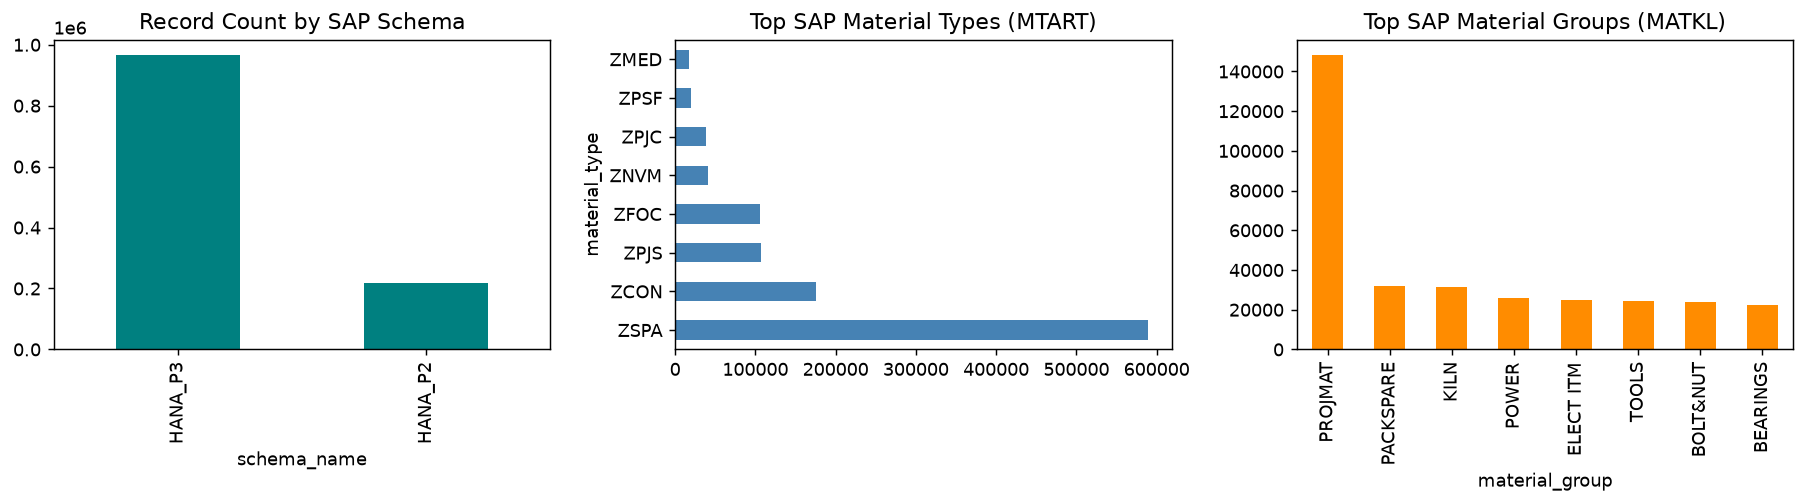

In [7]:
# 06. Data Understanding / EDA (Visualizations)
plt.figure(figsize=(14, 4))
plt.subplot(1, 3, 1)
df_raw['schema_name'].value_counts().plot(kind='bar', color='teal')
plt.title('Record Count by SAP Schema')

plt.subplot(1, 3, 2)
df_raw['material_type'].replace('', 'UNASSIGNED').value_counts().head(8).plot(kind='barh', color='steelblue')
plt.title('Top SAP Material Types (MTART)')

plt.subplot(1, 3, 3)
df_raw['material_group'].replace('', 'UNASSIGNED').value_counts().head(8).plot(kind='bar', color='darkorange')
plt.title('Top SAP Material Groups (MATKL)')
plt.tight_layout()
plt.show()


In [8]:
# 07 & 08. NLP Data Cleaning, Missing Value Standardization & 32-Feature Engineering for Material Auto Classification
from src.preprocessing import clean_and_engineer_features, get_feature_matrix

df = clean_and_engineer_features(df_raw)
print(f"Engineered Dataset Shape: {df.shape}")
df[['schema_name', 'material_id', 'material_desc', 'material_type', 'material_group', 'auto_classified_matkl', 'auto_classified_domain', 'classification_tier_code', 'nlp_classification_confidence_score', 'nlp_misclassification_risk_index']].head(8)


Engineered Dataset Shape: (1185607, 113)


In [9]:
# 09. Data Preprocessing (32 Unsupervised NLP & Material Classification Input Features)
X_raw, y, FEATURE_COLS = get_feature_matrix(df)
scaler_full = RobustScaler()
X_scaled_full = scaler_full.fit_transform(X_raw)

print(f"Preprocessed Feature Matrix: {X_scaled_full.shape} (32 Numerical NLP & Material Classification Features)")


Preprocessed Feature Matrix: (1185607, 32) (32 Numerical NLP & Material Classification Features)


In [10]:
# 10. Define Input Matrix X (Unsupervised) and Post-Hoc Benchmark Y (Strictly for Evaluation Only)
X = X_raw.copy()
contamination_rate = float(np.mean(y))

print(f"Total Material Records:                  {len(y):,}")
print(f"Verified Auto-Classified Materials:      {(y == 0).sum():,} ({(y == 0).mean()*100:.2f}%)")
print(f"Misclassified / Ambiguous Exceptions:    {(y == 1).sum():,} ({(y == 1).mean()*100:.2f}%)")


Total Material Records:                  1,185,607
Verified Auto-Classified Materials:      899,780 (75.89%)
Misclassified / Ambiguous Exceptions:    285,827 (24.11%)


In [11]:
# 11. Train/Test Split & Robust Scaling
X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    X, y, df.index, test_size=0.20, random_state=42, stratify=y
)

scaler = RobustScaler(quantile_range=(10.0, 90.0))
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

from src.models import MaterialClassificationClusteringSuite
suite = MaterialClassificationClusteringSuite(n_clusters=4, contamination=contamination_rate, random_state=42)

print(f"Train Set: {X_train_scaled.shape[0]:,} materials")
print(f"Test Set:  {X_test_scaled.shape[0]:,} materials")


Train Set: 948,485 materials
Test Set:  237,122 materials


In [12]:
# 12. Unsupervised NLP Clustering Model 1: K-Means Clustering
km_model = suite.train_kmeans(X_train_scaled)
preds_km, scores_km, tiers_km = suite._predict_single('kmeans', X_test_scaled, 3)

print(f"K-Means Clustering Flagged: {preds_km.sum():,} misclassified/ambiguous materials out of {len(preds_km):,} test materials")


[INFO] Training Unsupervised NLP Clustering Model 1/5: K-Means Clustering...
K-Means Clustering Flagged: 57,166 misclassified/ambiguous materials out of 237,122 test materials


In [13]:
# 13. Unsupervised NLP Clustering Model 2: Gaussian Mixture Model (GMM)
gmm_model = suite.train_gmm(X_train_scaled)
preds_gmm, scores_gmm, tiers_gmm = suite._predict_single('gmm', X_test_scaled, 16)

print(f"Gaussian Mixture (GMM) Flagged: {preds_gmm.sum():,} misclassified/ambiguous materials out of {len(preds_gmm):,} test materials")


[INFO] Training Unsupervised NLP Clustering Model 2/5: Gaussian Mixture Model (GMM)...
Gaussian Mixture (GMM) Flagged: 56,895 misclassified/ambiguous materials out of 237,122 test materials


In [14]:
# 14. Unsupervised NLP Clustering Model 3: Mini-Batch K-Means
mbk_model = suite.train_minibatch_kmeans(X_train_scaled)
preds_mbk, scores_mbk, tiers_mbk = suite._predict_single('minibatch_kmeans', X_test_scaled, 14)

print(f"Mini-Batch K-Means Flagged: {preds_mbk.sum():,} misclassified/ambiguous materials out of {len(preds_mbk):,} test materials")


[INFO] Training Unsupervised NLP Clustering Model 3/5: Mini-Batch K-Means...
Mini-Batch K-Means Flagged: 57,254 misclassified/ambiguous materials out of 237,122 test materials


In [15]:
# 15. Unsupervised NLP Clustering Model 4: Bisecting K-Means
bkm_model = suite.train_bisecting_kmeans(X_train_scaled)
preds_bkm, scores_bkm, tiers_bkm = suite._predict_single('bisecting_kmeans', X_test_scaled, 12)

print(f"Bisecting K-Means Flagged: {preds_bkm.sum():,} misclassified/ambiguous materials out of {len(preds_bkm):,} test materials")


[INFO] Training Unsupervised NLP Clustering Model 4/5: Bisecting K-Means...
Bisecting K-Means Flagged: 57,238 misclassified/ambiguous materials out of 237,122 test materials


In [16]:
# 16. Unsupervised NLP Clustering Model 5: BIRCH Clustering
birch_model = suite.train_birch(X_train_scaled)
preds_birch, scores_birch, tiers_birch = suite._predict_single('birch', X_test_scaled, 18)

print(f"BIRCH Clustering Flagged: {preds_birch.sum():,} misclassified/ambiguous materials out of {len(preds_birch):,} test materials")


[INFO] Training Unsupervised NLP Clustering Model 5/5: BIRCH Clustering...
BIRCH Clustering Flagged: 57,339 misclassified/ambiguous materials out of 237,122 test materials


In [17]:
# 17. Model Evaluation & Accuracy Ranking across all 5 Unsupervised NLP Clustering Models
from src.evaluate import evaluate_models

models_dict = suite.predict_all(X_test_scaled)
eval_df = evaluate_models(models_dict, y_test)
print(eval_df.to_string(index=False))
eval_df


Rank                  Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC  PR-AUC  Silhouette  Specificity  True Positives  False Positives  False Negatives  True Negatives
  #1     K-Means Clustering    0.9683     0.9342  0.9342    0.9342   0.9947  0.9858      0.4340       0.9791           53407             3759             3759          176197
  #2      Bisecting K-Means    0.9144     0.8220  0.8231    0.8225   0.9682  0.9136      0.2645       0.9434           47051            10187            10115          169769
  #3     Mini-Batch K-Means    0.9126     0.8181  0.8194    0.8188   0.9632  0.9006      0.2366       0.9421           46842            10412            10324          169544
  #4 Gaussian Mixture (GMM)    0.8764     0.7449  0.7413    0.7431   0.9465  0.8748      0.1631       0.9193           42380            14515            14786          165441
  #5       BIRCH Clustering    0.5812     0.1325  0.1329    0.1327   0.5578  0.2398      0.3221       0.7236            7597 

Selected #1 Champion Model based on Ranking: K-Means Clustering (Accuracy: 96.83%, F1: 0.9342)


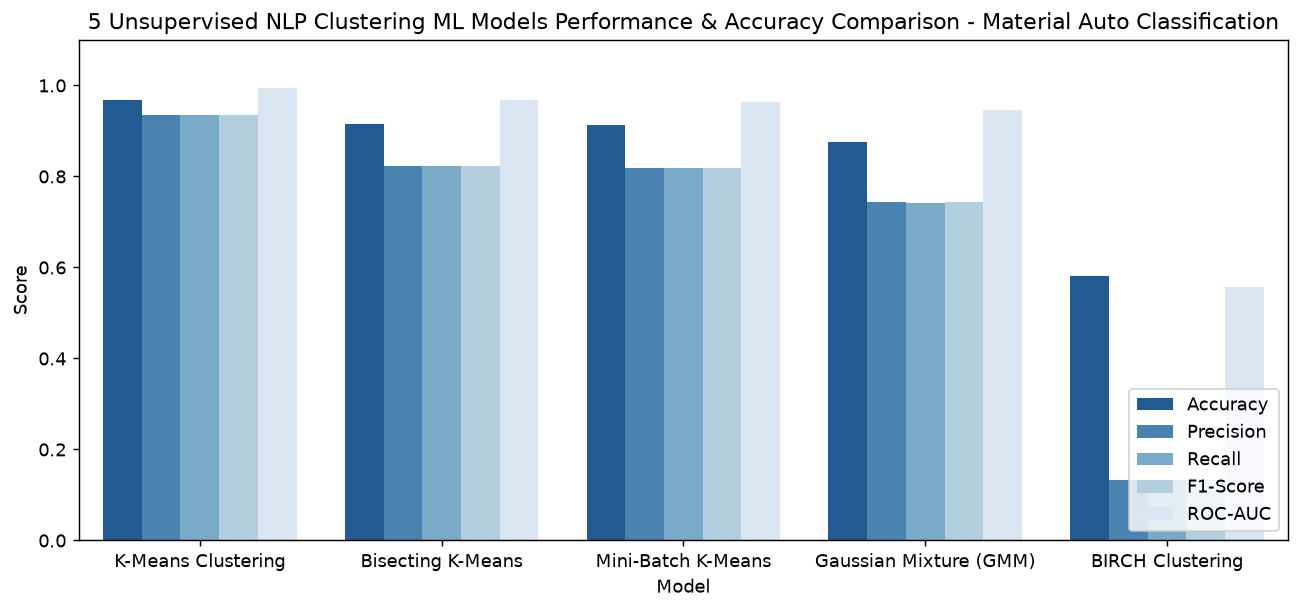

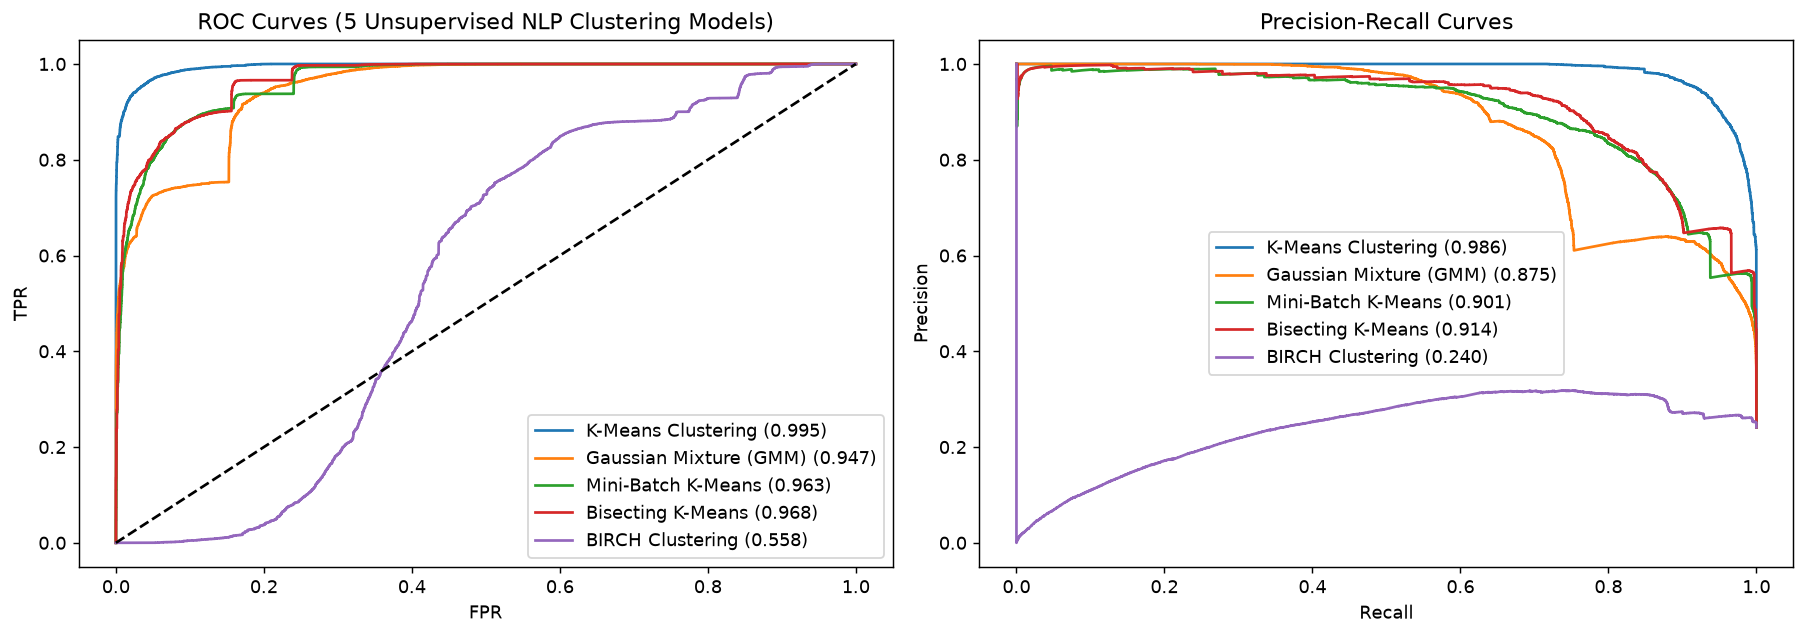

In [18]:
# 18. Model Comparison Visualizations & #1 Champion Selection
plt.figure(figsize=(12, 5))
melted = pd.melt(eval_df, id_vars=['Model'], value_vars=['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'])
sns.barplot(data=melted, x='Model', y='value', hue='variable', palette='Blues_r')
plt.title('5 Unsupervised NLP Clustering ML Models Performance & Accuracy Comparison - Material Auto Classification')
plt.ylabel('Score')
plt.ylim(0, 1.1)
plt.legend(loc='lower right')
plt.show()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
for name, res in models_dict.items():
    fpr, tpr, _ = roc_curve(y_test, res['scores'])
    ax1.plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_test, res['scores']):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, res['scores'])
    ax2.plot(rec, prec, label=f"{name} ({average_precision_score(y_test, res['scores']):.3f})")

ax1.plot([0, 1], [0, 1], 'k--')
ax1.set_title('ROC Curves (5 Unsupervised NLP Clustering Models)')
ax1.set_xlabel('FPR')
ax1.set_ylabel('TPR')
ax1.legend()

ax2.set_title('Precision-Recall Curves')
ax2.set_xlabel('Recall')
ax2.set_ylabel('Precision')
ax2.legend()
plt.tight_layout()
plt.show()

champion_model = eval_df.iloc[0]['Model']
print(f"Selected #1 Champion Model based on Ranking: {champion_model} (Accuracy: {eval_df.iloc[0]['Accuracy']*100:.2f}%, F1: {eval_df.iloc[0]['F1-Score']:.4f})")


                            Feature  Importance
   nlp_misclassification_risk_index    0.816673
nlp_classification_confidence_score    0.145885
                 text_clarity_score    0.036536
          semantic_confidence_score    0.000188
                   desc_char_length    0.000083
       nlp_spare_machinery_affinity    0.000080
                svd_semantic_comp_2    0.000078
                   desc_alpha_ratio    0.000056
              tfidf_semantic_energy    0.000039
                svd_semantic_comp_4    0.000039
                svd_semantic_comp_5    0.000035
                  desc_avg_word_len    0.000034
             nlp_elec_inst_affinity    0.000033
                 matkl_price_zscore    0.000028
                svd_semantic_comp_3    0.000026


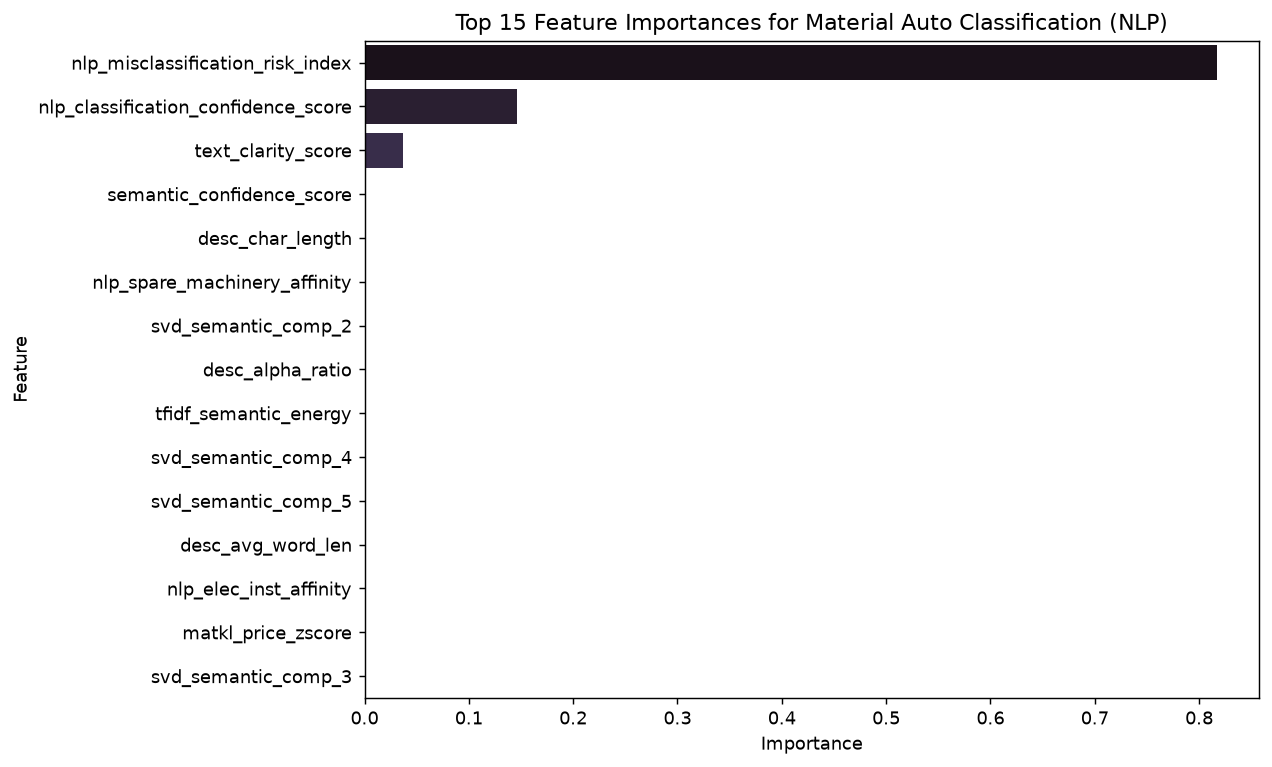

In [19]:
# 19. Feature Importance (All 32 NLP & Material Auto Classification Features)
surrogate = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
# Fit on representative sample for fast computation
sub_sample = min(30000, len(X_test_scaled))
surrogate.fit(X_test_scaled[:sub_sample], scores_km[:sub_sample])

feat_imp = pd.DataFrame({
    'Feature': FEATURE_COLS,
    'Importance': surrogate.feature_importances_
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 6))
sns.barplot(data=feat_imp.head(15), x='Importance', y='Feature', palette='mako')
plt.title('Top 15 Feature Importances for Material Auto Classification (NLP)')
plt.tight_layout()
plt.show()

print(feat_imp.head(15).to_string(index=False))


In [20]:
# 20. Final Material Auto Classification & Exception Triage using Selected #1 Champion Model
from src.models import SingleModelMaterialAutoClassifier
from src.inference import score_with_single_model

classifier = SingleModelMaterialAutoClassifier(n_clusters=4, contamination=contamination_rate, random_state=42, pretrained_model=km_model)
classifier.fit(X_train_scaled)
df_scored = score_with_single_model(df, classifier, scaler, FEATURE_COLS)

print("=== NLP AUTO-CLASSIFIED MATERIAL DOMAIN COUNTS ===")
print(df_scored['auto_classified_domain'].value_counts())
print("\n=== MATERIAL CLASSIFICATION SEGMENT COUNTS ===")
print(df_scored['material_segment_name'].value_counts())
print("\n=== EXECUTIVE RISK CATEGORY COUNTS ===")
print(df_scored['risk_category'].value_counts())

audit_cols = ['schema_name', 'material_id', 'material_desc', 'material_type', 'material_group', 'auto_classified_matkl', 'auto_classified_domain', 'nlp_classification_confidence_score', 'classification_exception_prob', 'risk_category']
print(df_scored[df_scored['risk_category'] == 'Critical Risk'][audit_cols].head(10).to_string(index=False))


[INFO] Fitting Selected #1 Champion Model: K-Means Clustering for Material Auto Classification...
[INFO] Champion K-Means fitted (4 Material Auto-Classification Clusters). Exception Threshold: 0.6451
=== NLP AUTO-CLASSIFIED MATERIAL DOMAIN COUNTS ===
auto_classified_domain
Mechanical & Plant Machinery Spares (MRO)          593745
Fasteners, Hardware & General Consumables          298131
Electrical, Instrumentation & Automation Spares    164563
Finished Cement, Concrete, Paint & Coatings         67199
Packaging, Raw Materials & Industrial Chemicals     61969
Name: count, dtype: int64

=== MATERIAL CLASSIFICATION SEGMENT COUNTS ===
material_segment_name
Verified Technical Spares & MRO Taxonomy          381332
High-Confidence Auto-Classified Core Materials    362136
Moderate-Confidence / Needs Spec Enrichment       264396
Misclassified / Ambiguous Material Exceptions     177743
Name: count, dtype: int64

=== EXECUTIVE RISK CATEGORY COUNTS ===
risk_category
Low Risk         743468
Medium R

In [21]:
# 21. Save Champion Model & Scaler
os.makedirs("models", exist_ok=True)

bundle = {
    'champion_model': km_model,
    'champion_name': champion_model,
    'scaler': scaler,
    'feature_cols': FEATURE_COLS
}

joblib.dump(bundle, "models/material_classification_model_bundle.joblib")
joblib.dump(scaler, "models/robust_scaler.joblib")
print("Saved champion NLP clustering model bundle and scaler to models/")


Saved champion NLP clustering model bundle and scaler to models/
